<a href="https://colab.research.google.com/github/luisdavid4564/BioSalud_backend-/blob/main/DATAFEST_2026_MASTER_COLAB_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATAFEST 2026 — CUADERNO MAESTRO (v2): MODELAMIENTO OUT-OF-TIME + VARIABLES HISTÓRICAS
### Predicción de la probabilidad de conversión de 9,900 clientes en Diciembre 2026

**Métrica oficial:** $Gini = 2 \times AUC - 1$

**Qué incluye esta versión**
- Comparación de Regresión Logística, CatBoost, LightGBM, XGBoost y un ensemble ponderado.
- Validación fuera de tiempo en dos particiones (Octubre y Noviembre).
- **Variables históricas por cliente** (rezagos y acumulados de meses anteriores), calculadas sin fuga temporal.
- **Promedio de varias semillas** por modelo para reducir varianza.
- **Prueba de ablación**: mide cuánto aportan las variables históricas.
- **Selección automática** del mejor modelo según Gini medio Oct–Nov.
- Verificación formal del archivo de entrega.

> Ejecuta `Entorno de ejecución → Ejecutar todo`. Tiempo aproximado en CPU de Colab: 10–20 min.

## 1. Entorno y dependencias

In [ ]:
!pip install --quiet catboost lightgbm xgboost scikit-learn matplotlib

import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

plt.rcParams.update({'font.family': 'sans-serif', 'axes.edgecolor': '#333333', 'axes.linewidth': 0.8,
                     'grid.color': '#e0e0e0', 'grid.linestyle': '--', 'grid.linewidth': 0.5})

SEEDS = [0, 1, 2]      # semillas promediadas por modelo (usa [0] para una corrida rápida)
print('✅ Entorno listo.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.6 MB/s eta 0:00:00
✅ Entorno listo.


## 2. Carga de datos
Busca los archivos en carpetas locales, en Google Drive o permite subirlos manualmente.

In [ ]:
import os
import pandas as pd

archivos = ['train.csv', 'test.csv', 'sample_submission.csv']

# Si faltan archivos, abre el selector de subida de Colab
if not all(os.path.exists(f) for f in archivos):
    from google.colab import files
    print('Selecciona train.csv, test.csv y sample_submission.csv')
    files.upload()

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample = pd.read_csv('sample_submission.csv')
print(f'train: {train.shape} | test: {test.shape} | sample_submission: {sample.shape}')

train: (110100, 25) | test: (9900, 24) | sample_submission: (9900, 2)


## 3. Auditoría de datos y regla de negocio

In [ ]:
print('=== AUDITORÍA DE DATOS ===')
print('Nulos train:', int(train.isnull().sum().sum()), '| Nulos test:', int(test.isnull().sum().sum()))
print('Duplicados [id_cliente, mes] en train:', int(train.duplicated(['id_cliente', 'mes']).sum()))

resumen = train.groupby('mes').agg(total_clientes=('id_cliente', 'count'),
                                   conversiones=('objetivo', 'sum'),
                                   tasa_conversion=('objetivo', 'mean')).reset_index()
resumen['tasa_pct'] = (resumen['tasa_conversion'] * 100).round(2)
display(resumen)
print(f"Tasa global de conversión: {train['objetivo'].mean()*100:.2f}%")

# Regla de negocio: un cliente que convierte no vuelve a aparecer
primer_conv = train[train.objetivo == 1].groupby('id_cliente')['mes'].min().rename('mes_conv')
t = train.merge(primer_conv, on='id_cliente', how='left')
reaparecen = int((t['mes'] > t['mes_conv']).sum())
print(f'\nFilas de clientes DESPUÉS de convertir: {reaparecen}')

en_train = test.id_cliente.isin(train.id_cliente)
print(f'Clientes de test ya presentes en train: {en_train.sum()} ({en_train.mean()*100:.1f}%) | '
      f'nuevos: {(~en_train).sum()} ({(~en_train).mean()*100:.1f}%)')

=== AUDITORÍA DE DATOS ===
Nulos train: 0 | Nulos test: 0
Duplicados [id_cliente, mes] en train: 0


,mes,total_clientes,conversiones,tasa_conversion,tasa_pct
0,202601,10400,1521,0.146250,14.62
1,202602,9800,1543,0.157449,15.74
2,202603,10300,1527,0.148252,14.83
3,202604,9600,1473,0.153438,15.34
4,202605,10100,1584,0.156832,15.68
5,202606,10350,1600,0.154589,15.46
6,202607,9700,1410,0.145361,14.54
7,202608,10050,1449,0.144179,14.42
8,202609,9900,1393,0.140707,14.07
9,202610,10400,1628,0.156538,15.65


Tasa global de conversión: 15.05%

Filas de clientes DESPUÉS de convertir: 0
Clientes de test ya presentes en train: 8061 (81.4%) | nuevos: 1839 (18.6%)


## 4. Variables: historial causal + ingeniería de características

**Idea clave:** las variables de historial se calculan **una sola vez sobre train+test concatenados y ordenados por cliente y mes**. Cada fila solo usa meses *anteriores* del mismo cliente (`shift(1)`, `cumcount`, acumulados desplazados), por lo que no hay fuga temporal en ninguna partición.

**Historial (6):** `meses_previos_observado`, `gap_prev`, `dui_lag1`, `dui_diff`, `dui_mean_prev`, `dui_min_prev`  
**Financieras (5):** `deuda_estimada`, `ingreso_disponible`, `saldo_por_producto`, `saldo_sobre_ingresos`, `saldo_sobre_deuda`  
**Recencia (4):** `dias_diff_trans_inter`, `min_dias_inactividad`, `max_dias_inactividad`, `recencia_inactividad`  
**Intensidad (4):** `productos_por_antiguedad`, `visitas_por_mes`, `total_servicios_activos`, `engagement_digital`  
**Riesgo (4):** `banda_riesgo_num`, `riesgo_x_productos`, `riesgo_x_min_dias`, `productos_x_min_dias`

In [ ]:
RAW_FEATURES = [
    'edad', 'ingresos', 'ratio_deuda_ingresos', 'antiguedad_cuenta_meses', 'numero_productos',
    'saldo_promedio', 'dias_ultima_transaccion', 'ocupacion', 'region', 'canal_adquisicion',
    'banda_riesgo', 'tiene_tarjeta_credito', 'activo_movil', 'es_nuevo_cliente', 'tiene_prestamo',
    'antiguedad_direccion_meses', 'visitas_web_ultimos_90_dias', 'distancia_sucursal_km',
    'dispositivo_principal', 'dia_preferido_pago', 'tiene_seguro', 'dias_ultima_interaccion']

HIST_FEATURES = ['meses_previos_observado', 'gap_prev', 'dui_lag1', 'dui_diff', 'dui_mean_prev', 'dui_min_prev']

BASE_DERIVED = [
    'deuda_estimada', 'ingreso_disponible', 'saldo_por_producto', 'saldo_sobre_ingresos', 'saldo_sobre_deuda',
    'dias_diff_trans_inter', 'min_dias_inactividad', 'max_dias_inactividad', 'recencia_inactividad',
    'productos_por_antiguedad', 'visitas_por_mes', 'total_servicios_activos', 'engagement_digital',
    'banda_riesgo_num', 'riesgo_x_productos', 'riesgo_x_min_dias', 'productos_x_min_dias']

CAT_FEATURES = ['ocupacion', 'region', 'canal_adquisicion', 'banda_riesgo', 'dispositivo_principal']

FEATS_BASE = RAW_FEATURES + BASE_DERIVED                 # sin historial (versión anterior)
FEATS_ALL = RAW_FEATURES + BASE_DERIVED + HIST_FEATURES  # con historial (versión final)


def build_dataset(train, test):
    # Une train y test, calcula historial causal y variables derivadas. Conserva el orden original.
    t = train.copy(); t['_es_test'] = 0
    s = test.copy();  s['_es_test'] = 1; s['objetivo'] = np.nan
    df = pd.concat([t, s], ignore_index=True)

    # booleanas -> 0/1
    for c in df.columns:
        if df[c].dtype == bool:
            df[c] = df[c].astype(int)

    # --- Historial causal (solo meses anteriores del mismo cliente) ---
    d = df.sort_values(['id_cliente', 'mes']).copy()
    d['_mi'] = (d['mes'] // 100 - 2026) * 12 + d['mes'] % 100 - 1
    g = d.groupby('id_cliente')
    d['meses_previos_observado'] = g.cumcount()
    d['gap_prev'] = d['_mi'] - g['_mi'].shift(1)
    d['dui_lag1'] = g['dias_ultima_interaccion'].shift(1)
    d['dui_diff'] = d['dias_ultima_interaccion'] - d['dui_lag1']
    d['dui_mean_prev'] = g['dias_ultima_interaccion'].transform(lambda x: x.expanding().mean().shift(1))
    d['dui_min_prev'] = g['dias_ultima_interaccion'].transform(lambda x: x.expanding().min().shift(1))
    df = d.sort_index().drop(columns=['_mi'])   # restaura el orden original

    # --- Variables derivadas (solo usan información de la misma fila) ---
    df['deuda_estimada'] = df['ingresos'] * df['ratio_deuda_ingresos']
    df['ingreso_disponible'] = df['ingresos'] * (1.0 - df['ratio_deuda_ingresos'])
    df['saldo_por_producto'] = df['saldo_promedio'] / np.maximum(df['numero_productos'], 1)
    df['saldo_sobre_ingresos'] = df['saldo_promedio'] / np.maximum(df['ingresos'], 1.0)
    df['saldo_sobre_deuda'] = df['saldo_promedio'] / np.maximum(df['deuda_estimada'] + 1.0, 1.0)

    df['dias_diff_trans_inter'] = (df['dias_ultima_transaccion'] - df['dias_ultima_interaccion']).abs()
    df['min_dias_inactividad'] = np.minimum(df['dias_ultima_transaccion'], df['dias_ultima_interaccion'])
    df['max_dias_inactividad'] = np.maximum(df['dias_ultima_transaccion'], df['dias_ultima_interaccion'])
    df['recencia_inactividad'] = 1.0 / (df['min_dias_inactividad'] + 1.0)

    df['productos_por_antiguedad'] = df['numero_productos'] / np.maximum(df['antiguedad_cuenta_meses'], 1)
    df['visitas_por_mes'] = df['visitas_web_ultimos_90_dias'] / 3.0
    df['total_servicios_activos'] = (df['tiene_tarjeta_credito'].astype(int) + df['activo_movil'].astype(int)
                                     + df['tiene_prestamo'].astype(int) + df['tiene_seguro'].astype(int))
    df['engagement_digital'] = df['activo_movil'].astype(int) * df['visitas_por_mes']

    df['banda_riesgo_num'] = df['banda_riesgo'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4}).fillna(2.5)
    df['riesgo_x_productos'] = df['banda_riesgo_num'] * df['numero_productos']
    df['riesgo_x_min_dias'] = df['banda_riesgo_num'] * df['min_dias_inactividad']
    df['productos_x_min_dias'] = df['numero_productos'] * df['min_dias_inactividad']

    # Categóricas: mismas categorías en todas las particiones (evita desajustes en LightGBM/XGBoost)
    for c in CAT_FEATURES:
        df[c] = df[c].astype(str)
    return df


df_all = build_dataset(train, test)
print('Dataset combinado:', df_all.shape)
print(f'Variables base: {len(FEATS_BASE)} | con historial: {len(FEATS_ALL)}')

# --- Prueba anti-fuga: el rezago debe ser el valor del mes anterior del mismo cliente ---
chk = df_all.sort_values(['id_cliente', 'mes'])
prev = chk.groupby('id_cliente')['dias_ultima_interaccion'].shift(1)
assert np.allclose(chk['dui_lag1'].fillna(-1), prev.fillna(-1)), 'Fuga o error en dui_lag1'
assert (df_all.loc[df_all._es_test == 1, 'id_cliente'].values == test['id_cliente'].values).all(), 'Orden de test alterado'
assert (df_all.loc[df_all._es_test == 0, 'id_cliente'].values == train['id_cliente'].values).all(), 'Orden de train alterado'
print('✅ Verificaciones anti-fuga y de orden superadas.')

Dataset combinado: (120000, 49)
Variables base: 39 | con historial: 45
✅ Verificaciones anti-fuga y de orden superadas.


## 5. Particiones temporales estrictas (Out-of-Time)


In [ ]:
lab = df_all[df_all._es_test == 0].copy()
lab['objetivo'] = lab['objetivo'].astype(int)

train_oct, eval_oct = lab[lab.mes <= 202609], lab[lab.mes == 202610]
train_nov, eval_nov = lab[lab.mes <= 202610], lab[lab.mes == 202611]
test_df = df_all[df_all._es_test == 1].copy()

print(f'Octubre:   train={len(train_oct):,} | eval={len(eval_oct):,}')
print(f'Noviembre: train={len(train_nov):,} | eval={len(eval_nov):,}')
print(f'Producción: train={len(lab):,} | test={len(test_df):,}')

Octubre:   train=90,200 | eval=10,400
Noviembre: train=100,600 | eval=9,500
Producción: train=110,100 | test=9,900


## 6. Métrica oficial y evaluación de ranking

In [ ]:
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, roc_curve

def evaluate_ranking(y_true, p, model_name='Modelo', period_name=''):
    y_true = pd.Series(np.asarray(y_true)).reset_index(drop=True)
    p = np.asarray(p)
    auc = roc_auc_score(y_true, p)
    gini = 2.0 * auc - 1.0
    d = pd.DataFrame({'y': y_true, 'p': p})
    d['decil'] = pd.qcut(d['p'].rank(method='first', ascending=False), q=10, labels=False) + 1
    tot_pos, base = d['y'].sum(), d['y'].mean()
    s = d.groupby('decil').agg(total=('y', 'count'), positivos=('y', 'sum'), tasa_conversion=('y', 'mean')).reset_index()
    s['captura_pct'] = s['positivos'] / tot_pos
    s['captura_acum'] = s['captura_pct'].cumsum()
    s['lift'] = s['tasa_conversion'] / base
    s['lift_acum'] = (s['captura_acum'] / (s['decil'] * 0.1)).round(2)
    resumen = {
        'modelo': model_name, 'periodo': period_name, 'roc_auc': round(auc, 4), 'gini': round(gini, 4),
        'top10_captura': round(s.loc[s.decil == 1, 'captura_pct'].values[0] * 100, 2),
        'top20_captura': round(s.loc[s.decil == 2, 'captura_acum'].values[0] * 100, 2),
        'top30_captura': round(s.loc[s.decil == 3, 'captura_acum'].values[0] * 100, 2),
        'top20_lift': s.loc[s.decil == 2, 'lift_acum'].values[0],
        'brier': round(brier_score_loss(y_true, p), 4), 'log_loss': round(log_loss(y_true, p), 4)}
    return resumen, s

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

## 7. Definición de modelos (promedio de varias semillas)
Una sola función entrena cualquier modelo y devuelve la probabilidad promedio de las semillas en `SEEDS`.  


In [ ]:
from catboost import CatBoostClassifier
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Categorías fijas a partir de todos los datos (train + test)
CAT_LEVELS = {c: sorted(df_all[c].unique()) for c in CAT_FEATURES}

def to_category(X):
    X = X.copy()
    for c in CAT_FEATURES:
        X[c] = pd.Categorical(X[c], categories=CAT_LEVELS[c])
    return X

def fit_predict(name, tr, ev, feats, seeds=SEEDS, keep_models=False):
    # Entrena `name` en `tr` y predice sobre `ev`. Devuelve (probabilidades, modelos).
    Xtr, ytr, Xev = tr[feats].copy(), tr['objetivo'].astype(int), ev[feats].copy()
    cats = [c for c in CAT_FEATURES if c in feats]
    nums = [f for f in feats if f not in cats]
    preds, models = [], []

    for sd in seeds:
        if name == 'Regresión Logística':
            prep = ColumnTransformer([
                ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), nums),
                ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cats)])
            m = Pipeline([('prep', prep), ('clf', LogisticRegression(C=0.1, max_iter=2000, random_state=sd))])
            m.fit(Xtr, ytr); p = m.predict_proba(Xev)[:, 1]

        elif name == 'CatBoost':
            idx = [feats.index(c) for c in cats]
            m = CatBoostClassifier(iterations=800, learning_rate=0.03, depth=6, l2_leaf_reg=4.0,
                                   random_seed=sd, eval_metric='AUC', verbose=0)
            m.fit(Xtr, ytr, cat_features=idx, verbose=False); p = m.predict_proba(Xev)[:, 1]

        elif name == 'LightGBM':
            m = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.02, num_leaves=25, max_depth=6,
                                   min_child_samples=80, colsample_bytree=0.7, subsample=0.8, subsample_freq=1,
                                   reg_alpha=0.5, reg_lambda=2.0, random_state=sd, verbose=-1)
            m.fit(to_category(Xtr), ytr); p = m.predict_proba(to_category(Xev))[:, 1]

        elif name == 'XGBoost':
            m = xgb.XGBClassifier(n_estimators=500, learning_rate=0.02, max_depth=5, colsample_bytree=0.7,
                                  subsample=0.8, reg_alpha=0.5, reg_lambda=2.0, enable_categorical=True,
                                  tree_method='hist', random_state=sd, eval_metric='logloss')
            m.fit(to_category(Xtr), ytr); p = m.predict_proba(to_category(Xev))[:, 1]
        else:
            raise ValueError(name)
        preds.append(p)
        if keep_models: models.append(m)
    return np.mean(preds, axis=0), models

W_ENS = {'CatBoost': 0.45, 'XGBoost': 0.30, 'LightGBM': 0.15, 'Regresión Logística': 0.10}
MODELOS = list(W_ENS.keys())

def run_experiment(tr, ev, periodo, feats):
    # Entrena los 4 modelos + ensemble y devuelve (tabla de resultados, dict de predicciones).
    preds, rows = {}, []
    for nm in MODELOS:
        t0 = time.time()
        preds[nm], _ = fit_predict(nm, tr, ev, feats)
        r, _ = evaluate_ranking(ev['objetivo'], preds[nm], nm, periodo); rows.append(r)
        print(f'  {nm:<22} Gini={r["gini"]:.4f}  ({time.time()-t0:.0f}s)')
    preds['Ensemble'] = sum(W_ENS[k] * preds[k] for k in MODELOS)
    r, _ = evaluate_ranking(ev['objetivo'], preds['Ensemble'], 'Ensemble', periodo); rows.append(r)
    print(f'  {"Ensemble":<22} Gini={r["gini"]:.4f}')
    return pd.DataFrame(rows), preds

## 8. FASE 1 — Benchmark Octubre (entrena Ene–Sep, evalúa Octubre)

In [ ]:
print('=== OCTUBRE 2026 ===')
df_res_oct, preds_oct = run_experiment(train_oct, eval_oct, 'Octubre', FEATS_ALL)
display(df_res_oct)

=== OCTUBRE 2026 ===
  CatBoost               Gini=0.2682  (462s)
  XGBoost                Gini=0.2666  (46s)
  LightGBM               Gini=0.2657  (50s)
  Regresión Logística    Gini=0.2391  (5s)
  Ensemble               Gini=0.2688


,modelo,periodo,roc_auc,gini,top10_captura,top20_captura,top30_captura,top20_lift,brier,log_loss
0,CatBoost,Octubre,0.6341,0.2682,20.82,33.42,43.98,1.67,0.1273,0.4168
1,XGBoost,Octubre,0.6333,0.2666,21.07,33.72,44.29,1.69,0.1272,0.4164
2,LightGBM,Octubre,0.6329,0.2657,21.19,33.48,44.53,1.67,0.1272,0.4165
3,Regresión Logística,Octubre,0.6195,0.2391,19.35,32.19,44.04,1.61,0.1288,0.4221
4,Ensemble,Octubre,0.6344,0.2688,21.01,33.54,44.29,1.68,0.1272,0.4166


## 9. FASE 2 — Validación reservada Noviembre (entrena Ene–Oct, evalúa Noviembre)

In [ ]:
print('=== NOVIEMBRE 2026 ===')
df_res_nov, preds_nov = run_experiment(train_nov, eval_nov, 'Noviembre', FEATS_ALL)
display(df_res_nov)

=== NOVIEMBRE 2026 ===
  CatBoost               Gini=0.2380  (504s)
  XGBoost                Gini=0.2258  (53s)
  LightGBM               Gini=0.2249  (52s)
  Regresión Logística    Gini=0.2015  (6s)
  Ensemble               Gini=0.2324


,modelo,periodo,roc_auc,gini,top10_captura,top20_captura,top30_captura,top20_lift,brier,log_loss
0,CatBoost,Noviembre,0.6190,0.2380,18.97,30.37,41.21,1.52,0.1248,0.4109
1,XGBoost,Noviembre,0.6129,0.2258,18.76,29.60,40.03,1.48,0.1250,0.4114
2,LightGBM,Noviembre,0.6125,0.2249,19.18,29.46,39.82,1.47,0.1250,0.4114
3,Regresión Logística,Noviembre,0.6008,0.2015,16.40,29.33,40.31,1.47,0.1264,0.4172
4,Ensemble,Noviembre,0.6162,0.2324,19.32,29.53,40.31,1.48,0.1249,0.4112


## 10. Estabilidad temporal y selección automática del modelo

,modelo,gini_oct,gini_nov,gini_medio,delta_gini,variacion_pct,top20_captura_nov,top20_lift_nov
0,CatBoost,0.2682,0.2380,0.2531,-0.0302,-11.26,30.37,1.52
1,Ensemble,0.2688,0.2324,0.2506,-0.0364,-13.54,29.53,1.48
2,XGBoost,0.2666,0.2258,0.2462,-0.0408,-15.30,29.60,1.48
3,LightGBM,0.2657,0.2249,0.2453,-0.0408,-15.36,29.46,1.47
4,Regresión Logística,0.2391,0.2015,0.2203,-0.0376,-15.73,29.33,1.47



🏆 Modelo seleccionado (mayor Gini medio Oct–Nov): CatBoost
ℹ️ Ventaja sobre Ensemble < 0.005 de Gini: diferencia no concluyente (dentro del ruido).


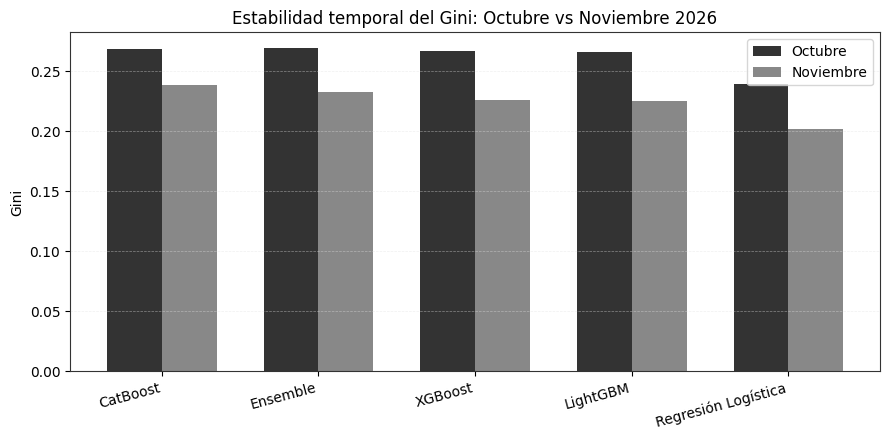

Gini ensemble / mejor modelo por mes ya mostrado arriba. Guardando tablas...


In [ ]:
df_comp = pd.merge(df_res_oct[['modelo', 'gini', 'roc_auc', 'top20_captura', 'top20_lift']],
                   df_res_nov[['modelo', 'gini', 'roc_auc', 'top20_captura', 'top20_lift']],
                   on='modelo', suffixes=('_oct', '_nov'))
df_comp['gini_medio'] = ((df_comp.gini_oct + df_comp.gini_nov) / 2).round(4)
df_comp['delta_gini'] = (df_comp.gini_nov - df_comp.gini_oct).round(4)
df_comp['variacion_pct'] = (df_comp.delta_gini / df_comp.gini_oct * 100).round(2)
df_comp = df_comp.sort_values('gini_medio', ascending=False).reset_index(drop=True)
display(df_comp[['modelo', 'gini_oct', 'gini_nov', 'gini_medio', 'delta_gini', 'variacion_pct',
                 'top20_captura_nov', 'top20_lift_nov']])

MEJOR = df_comp.loc[0, 'modelo']
print(f'\n🏆 Modelo seleccionado (mayor Gini medio Oct–Nov): {MEJOR}')
if len(df_comp) > 1 and (df_comp.loc[0, 'gini_medio'] - df_comp.loc[1, 'gini_medio']) < 0.005:
    print(f'ℹ️ Ventaja sobre {df_comp.loc[1, "modelo"]} < 0.005 de Gini: diferencia no concluyente (dentro del ruido).')

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(df_comp)); w = 0.35
ax.bar(x - w/2, df_comp.gini_oct, w, label='Octubre', color='#333333')
ax.bar(x + w/2, df_comp.gini_nov, w, label='Noviembre', color='#888888')
ax.set_ylabel('Gini'); ax.set_title('Estabilidad temporal del Gini: Octubre vs Noviembre 2026')
ax.set_xticks(x); ax.set_xticklabels(df_comp.modelo, rotation=15, ha='right')
ax.legend(); ax.grid(axis='y', alpha=0.5); plt.tight_layout(); plt.show()

# Gini por mes de validación (visión del Código 1)
print('Gini ensemble / mejor modelo por mes ya mostrado arriba. Guardando tablas...')
df_res_oct.to_csv('resultados_octubre.csv', index=False)
df_res_nov.to_csv('resultados_noviembre.csv', index=False)
df_comp.to_csv('comparacion_estabilidad.csv', index=False)

## 11. Curvas ROC y lift por decil (Noviembre)

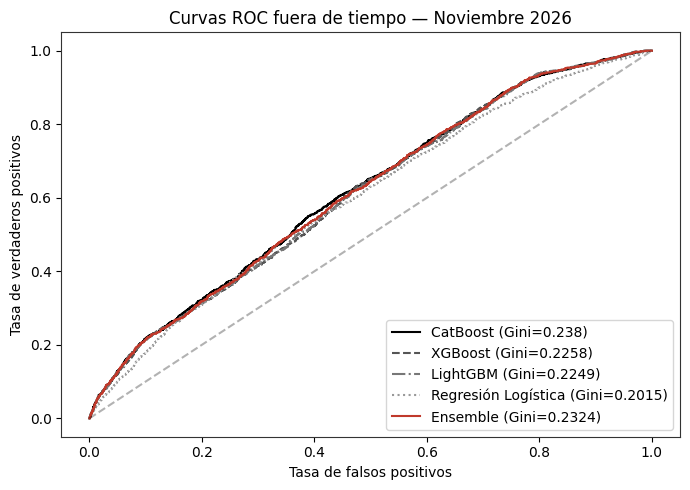

Tabla de deciles — CatBoost (decil 1 = mayor propensión)


,decil,total,positivos,tasa_conversion,captura_pct,captura_acum,lift,lift_acum
0,1,950,273,0.2874,0.1897,0.1897,1.8972,1.90
1,2,950,164,0.1726,0.1140,0.3037,1.1397,1.52
2,3,950,156,0.1642,0.1084,0.4121,1.0841,1.37
3,4,950,169,0.1779,0.1174,0.5295,1.1744,1.32
4,5,950,145,0.1526,0.1008,0.6303,1.0076,1.26
5,6,950,136,0.1432,0.0945,0.7248,0.9451,1.21
6,7,950,141,0.1484,0.0980,0.8228,0.9798,1.18
7,8,950,139,0.1463,0.0966,0.9194,0.9659,1.15
8,9,950,66,0.0695,0.0459,0.9653,0.4587,1.07
9,10,950,50,0.0526,0.0347,1.0000,0.3475,1.00


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
estilos = {'CatBoost': ('#000000', '-'), 'XGBoost': ('#555555', '--'), 'LightGBM': ('#777777', '-.'),
           'Regresión Logística': ('#999999', ':'), 'Ensemble': ('#c0392b', '-')}
for nm, (col, ls) in estilos.items():
    fpr, tpr, _ = roc_curve(eval_nov['objetivo'], preds_nov[nm])
    g = df_res_nov.loc[df_res_nov.modelo == nm, 'gini'].values[0]
    ax.plot(fpr, tpr, color=col, linestyle=ls, label=f'{nm} (Gini={g})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_title('Curvas ROC fuera de tiempo — Noviembre 2026')
ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

_, dec = evaluate_ranking(eval_nov['objetivo'], preds_nov[MEJOR], MEJOR, 'Noviembre')
print(f'Tabla de deciles — {MEJOR} (decil 1 = mayor propensión)')
display(dec.round(4))

## 12. Ablación: ¿aportan valor las variables históricas?
Se entrena CatBoost (1 semilla) **sin** y **con** las variables de historial en ambas particiones. Útil para justificar la mejora en el informe.

In [ ]:
filas = []
for nm_f, feats in [('Sin historial', FEATS_BASE), ('Con historial', FEATS_ALL)]:
    for per, tr, ev in [('Octubre', train_oct, eval_oct), ('Noviembre', train_nov, eval_nov)]:
        p, _ = fit_predict('CatBoost', tr, ev, feats, seeds=[0])
        filas.append({'variables': nm_f, 'periodo': per, 'n_variables': len(feats), 'gini': round(gini(ev['objetivo'], p), 4)})
abl = pd.DataFrame(filas).pivot(index='variables', columns='periodo', values='gini')
abl['medio'] = abl.mean(axis=1).round(4)
abl.loc['Mejora (con - sin)'] = abl.loc['Con historial'] - abl.loc['Sin historial']
display(abl.round(4))
print('Nota: mejoras < ~0.01 de Gini están dentro del ruido de muestreo; repórtalas como "no concluyentes".')

periodo,Noviembre,Octubre,medio
variables,,,
Con historial,0.2382,0.2664,0.2523
Sin historial,0.2298,0.2636,0.2467
Mejora (con - sin),0.0084,0.0028,0.0056


Nota: mejoras < ~0.01 de Gini están dentro del ruido de muestreo; repórtalas como "no concluyentes".


## 13. Entrenamiento final (Ene–Nov) e inferencia en Diciembre
Se reentrena el modelo seleccionado con las 110,100 observaciones y se predice sobre `test.csv`.

=== ENTRENAMIENTO FINAL: CatBoost | semillas=[0, 1, 2] ===
✅ Listo en 556s


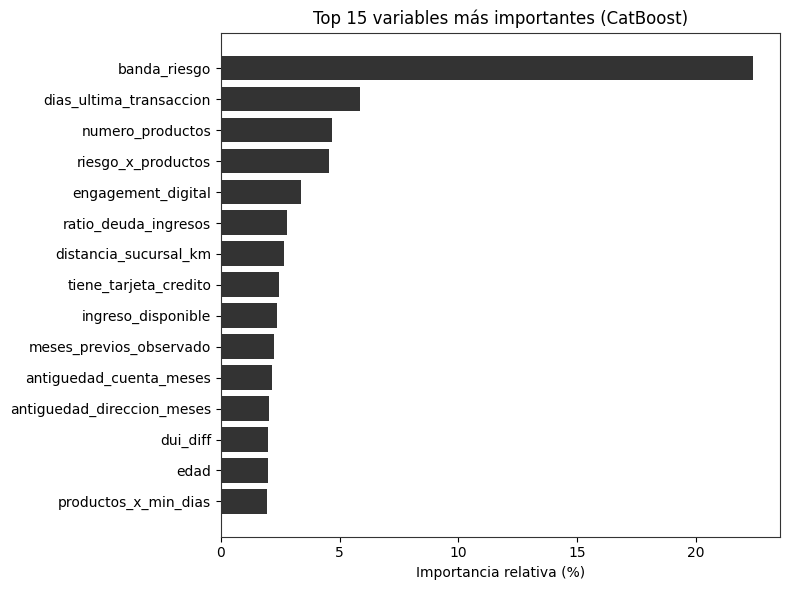

,feature,importancia
10,banda_riesgo,22.429
6,dias_ultima_transaccion,5.852
4,numero_productos,4.672
36,riesgo_x_productos,4.563
34,engagement_digital,3.358
2,ratio_deuda_ingresos,2.773
17,distancia_sucursal_km,2.676
11,tiene_tarjeta_credito,2.469
23,ingreso_disponible,2.371
39,meses_previos_observado,2.236


In [ ]:
print(f'=== ENTRENAMIENTO FINAL: {MEJOR} | semillas={SEEDS} ===')
t0 = time.time()

if MEJOR == 'Ensemble':
    comp = {}
    for nm in MODELOS:
        comp[nm], mods = fit_predict(nm, lab, test_df, FEATS_ALL, keep_models=(nm == 'CatBoost'))
        if nm == 'CatBoost': cb_models = mods
    preds_test = sum(W_ENS[k] * comp[k] for k in MODELOS)
else:
    preds_test, mods = fit_predict(MEJOR, lab, test_df, FEATS_ALL, keep_models=True)
    cb_models = mods if MEJOR == 'CatBoost' else []

print(f'✅ Listo en {time.time()-t0:.0f}s')

# Importancia de variables (CatBoost si está disponible; si no, se entrena una semilla solo para el gráfico)
if not cb_models:
    _, cb_models = fit_predict('CatBoost', lab, test_df, FEATS_ALL, seeds=[0], keep_models=True)
imp = np.mean([m.get_feature_importance() for m in cb_models], axis=0)
df_fi = pd.DataFrame({'feature': FEATS_ALL, 'importancia': imp}).sort_values('importancia', ascending=False)
df_fi.to_csv('importancia_variables.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 6))
top = df_fi.head(15)
ax.barh(top.feature[::-1], top.importancia[::-1], color='#333333')
ax.set_title('Top 15 variables más importantes (CatBoost)'); ax.set_xlabel('Importancia relativa (%)')
plt.tight_layout(); plt.show()
display(df_fi.head(15).round(3))

## 14. Archivo de entrega

In [ ]:
submission = pd.DataFrame({'id_cliente': test['id_cliente'].values, 'prediccion': np.clip(preds_test, 0, 1)})
OUT = 'submission.csv'
submission.to_csv(OUT, index=False)
print(f'✅ Generado: {OUT} {submission.shape}')
display(submission.head())
display(submission['prediccion'].describe())

✅ Generado: submission.csv (9900, 2)


,id_cliente,prediccion
0,2,0.149404
1,3,0.080278
2,7,0.132434
3,10,0.062427
4,11,0.150918


,prediccion
count,9900.000000
mean,0.144113
std,0.061592
min,0.022294
25%,0.118038
50%,0.140572
75%,0.161507
max,0.497255


## 15. Certificación formal del archivo (10 pruebas)

In [ ]:
checks = []
def chk(nombre, ok, evidencia): checks.append((nombre, bool(ok), evidencia))

chk('1. Filas = 9,900', len(submission) == 9900, f'{len(submission)}')
chk('2. Columnas [id_cliente, prediccion]', list(submission.columns) == ['id_cliente', 'prediccion'], list(submission.columns))
chk('3. Mismo orden e IDs que test.csv', (submission.id_cliente.values == test.id_cliente.values).all(), '')
chk('4. Estructura idéntica a sample_submission.csv',
    list(submission.columns) == list(sample.columns) and len(submission) == len(sample)
    and (submission.id_cliente.values == sample.id_cliente.values).all(), '')
chk('5. IDs únicos', submission.id_cliente.nunique() == 9900, submission.id_cliente.nunique())
chk('6. Sin nulos', submission.isnull().sum().sum() == 0, int(submission.isnull().sum().sum()))
chk('7. Rango [0, 1]', submission.prediccion.between(0, 1).all(),
    f'min={submission.prediccion.min():.4f}, max={submission.prediccion.max():.4f}')
chk('8. Scoring no colapsado (std > 0.01)', submission.prediccion.std() > 0.01, f'std={submission.prediccion.std():.4f}')
chk('9. Media cercana a tasa histórica (0.10–0.20)', 0.10 <= submission.prediccion.mean() <= 0.20,
    f'media={submission.prediccion.mean():.4f} (histórica={train.objetivo.mean():.4f})')
chk('10. Número de valores distintos > 5,000', submission.prediccion.nunique() > 5000, submission.prediccion.nunique())

df_checks = pd.DataFrame(checks, columns=['Criterio', 'Conforme', 'Evidencia'])
display(df_checks)
print('\n🏆 CERTIFICACIÓN APROBADA' if df_checks.Conforme.all() else '\n❌ REVISAR criterios fallidos')

,Criterio,Conforme,Evidencia
0,"1. Filas = 9,900",True,9900
1,"2. Columnas [id_cliente, prediccion]",True,"[id_cliente, prediccion]"
2,3. Mismo orden e IDs que test.csv,True,
3,4. Estructura idéntica a sample_submission.csv,True,
4,5. IDs únicos,True,9900
5,6. Sin nulos,True,0
6,"7. Rango [0, 1]",True,"min=0.0223, max=0.4973"
7,8. Scoring no colapsado (std > 0.01),True,std=0.0616
8,9. Media cercana a tasa histórica (0.10–0.20),True,media=0.1441 (histórica=0.1505)
9,"10. Número de valores distintos > 5,000",True,9900



🏆 CERTIFICACIÓN APROBADA


In [ ]:
# Descarga directa en Colab (descarga también las tablas para el informe)
try:
    from google.colab import files
    for f in ['submission.csv', 'resultados_octubre.csv', 'resultados_noviembre.csv',
              'comparacion_estabilidad.csv', 'importancia_variables.csv']:
        files.download(f)
except Exception:
    print('Fuera de Colab: archivos guardados en la carpeta actual.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>